In [1]:
# No slidiing window, cluster all the tasks at once
import sys
sys.path.append('C:\\Program Files\\IBM\\ILOG\\CPLEX_Studio210\\cplex\\python\\20.1\\x64_win64')
sys.path.append("C:\\ProgramData\\anaconda3\\Lib\\site-packages")
import numpy as np
import pandas as pd
from docplex.mp.model import Model
import matplotlib.pyplot as plt
import random

# define the parameters
PARAMS = {
    'P': 10,        # number of caissons
    'T': 90,      # horizon
    'Cmax':5,      # maximum number of tasks of one cluster
    'window_size': 30,   # window size 10
    'advanced': 3,          # advanced time
    'K': 5.993         # leakage coefficient
}   

# initialize the random values
random.seed(42)
# alpha_values = [round(random.uniform(0.03, 0.08), 3) for _ in range(PARAMS['P'])]
alpha_values = [round(random.uniform(0.01, 0.05), 3) for _ in range(PARAMS['P'])]   # degradation rate for each caisson
initial_p_values = [round(random.uniform(3.2, 3.5), 2) for i in range(PARAMS['P'])]
print("alpha values:", alpha_values)

# function to group the tasks within a window
def clustering_CR(df, T):
    if df.empty or T < 1:
        print("warning: task set is empty or horizon T is invalid")
        return df

    N = df.shape[0]
    data_pos_num = T + 1   # 或更改为最大DATE+1更紧凑
    mdl = Model('Global_Task_Clustering')
    theta = mdl.binary_var_matrix(N, data_pos_num, name='theta')
    cluster = mdl.binary_var_list(data_pos_num, name='cluster')

    a = [max(0, df.iloc[n]['DATE'] - PARAMS['advanced']) for n in range(N)]
    b = [min(data_pos_num, df.iloc[n]['DATE'] + int((3.2 - 3.0)/alpha_values[int(df.iloc[n]["CSEM"])]) - 2) for n in range(N)]

    mdl.minimize(mdl.sum(cluster[t] for t in range(data_pos_num)))
    mdl.add_constraints(theta[n, t] <= cluster[t] for n in range(N) for t in range(data_pos_num))
    mdl.add_constraints(mdl.sum(theta[n, t] for t in range(data_pos_num)) == 1 for n in range(N))
    mdl.add_constraints(mdl.sum(theta[n, t] for n in range(N)) <= PARAMS['Cmax'] for t in range(data_pos_num))
    for n in range(N):
        for t in range(data_pos_num):
            mdl.add_constraint(t * theta[n, t] + a[n] * (1 - theta[n, t]) >= a[n])
            mdl.add_constraint(t * theta[n, t] + b[n] * (1 - theta[n, t]) <= b[n])

    solution = mdl.solve()
    if not solution:
        print(f"Failed to solve the problem: {mdl.solve_details.status}")
        return None

    centers = {}
    for n in range(N):
        for t in range(data_pos_num):
            if solution.get_value(theta[n, t]) == 1.0:
                centers[n] = t
                break
    if 'INDEX' not in df.columns:
        df['INDEX'] = df.index  # 保证唯一性
    for n in range(N):
        df.loc[df['INDEX'] == df.iloc[n]['INDEX'], 'CENTER'] = centers.get(n, 0)
    return df


# function to calculate the gas leakage before clustering
def calculate_gas_leakage_before(df, T):
    total_leakage = 0

    for csem in df['CSEM'].unique():
        # filter the data for the current CSEM
        csem_data = df[df['CSEM'] == csem]
        x_operations = csem_data[csem_data['OPERATION'] == 'x']
        y_operations = csem_data[csem_data['OPERATION'] == 'y']

        # if there are more than two CR, add 1.80 for each additional CR (apart from these two) and calculate the leakage for the first and last CR independently
        if len(x_operations) >= 2:
            total_leakage += 1.80 * (len(x_operations) - 1)

        # deal with the first 'x' operation
        first_x = x_operations.iloc[0]
        if not pd.isna(first_x['INITIALP']):
            total_leakage += (first_x['INITIALP'] - 3.2) * PARAMS['K']

        # deal with the last 'x' operation
        last_x = x_operations.iloc[-1]
        if not y_operations.empty:
            # if there is a 'y' operation
            total_leakage += 1.80
        else:
            # if there is no 'y' operation
            alpha = alpha_values[last_x['CSEM']]
            total_leakage += (T - last_x['DATE'] - 1) * alpha * PARAMS['K']

    return total_leakage

# function to calculate the gas leakage after clustering
def calculate_gas_leakage_after(df, T):
    total_leakage = 0

    for csem in df['CSEM'].unique():
        # filter the data for the current CSEM
        csem_data = df[df['CSEM'] == csem]
        x_operations = csem_data[csem_data['OPERATION'] == 'x']
        y_operations = csem_data[csem_data['OPERATION'] == 'y']
        alpha = alpha_values[csem]

        # deal with the 'x' operations in the middle
        for i in range(1, len(x_operations)):
            current_x = x_operations.iloc[i]
            previous_x = x_operations.iloc[i - 1]
            center_diff = current_x['CENTER'] - previous_x['CENTER'] - 1
            total_leakage += center_diff * alpha * PARAMS['K']

        # deal with the first 'x' operation
        if not x_operations.empty:
            first_x = x_operations.iloc[0]
            total_leakage += first_x['CENTER'] * alpha * PARAMS['K']

        # deal with the last 'x' operation
        last_x = x_operations.iloc[-1]
        if not y_operations.empty:
            # if there is a 'y' operation
            y_center = y_operations['CENTER'].iloc[0]
            total_leakage += (y_center - last_x['CENTER']) * alpha * PARAMS['K']
        else:
            # if there is no 'y' operation
            total_leakage += (T - last_x['DATE'] - 1) * alpha * PARAMS['K']

    return total_leakage

def main():
    df = pd.read_csv('maintenance_plan.csv')
    if 'INDEX' not in df.columns:
        df['INDEX'] = df.index
    df['CENTER'] = df['DATE']
    clustered_df = clustering_CR(df[df['OPERATION']=='x'], PARAMS['T'])
    if clustered_df is not None:
        center_map = clustered_df.set_index('INDEX')['CENTER']
        df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)
    # 'y'操作直接CENTER=DATE
    df.loc[df['OPERATION'] == "y", 'CENTER'] = df.loc[df['OPERATION'] == "y", 'DATE']
    return df




alpha values: [0.036, 0.011, 0.021, 0.019, 0.039, 0.037, 0.046, 0.013, 0.027, 0.011]


In [2]:
result_df = main() # without sliding window

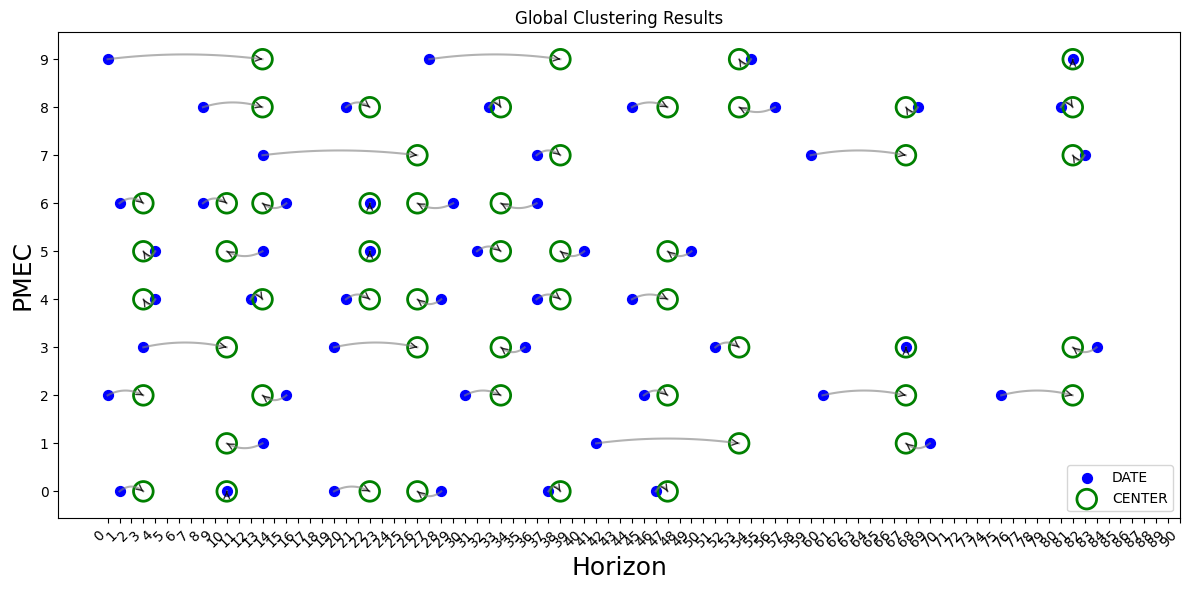

In [3]:
# print the results - no sliding window
def plot_df(df):
    fig, ax = plt.subplots(figsize=(12, 6))
    
    df_x = df[df['OPERATION'] == 'x']
    
    # 画“DATE”点
    ax.scatter(df_x['DATE'], df_x['CSEM'], color='blue', marker='o', label='DATE', s=50)
    # 画“CENTER”点
    ax.scatter(df_x['CENTER'], df_x['CSEM'], edgecolors='green', facecolors='none', marker='o', label='CENTER', s=200, linewidths=2)
    
    # 画箭头表示从DATE到CENTER的变化
    for j in range(len(df_x)):
        x_start, y_start = df_x['DATE'].iloc[j], df_x['CSEM'].iloc[j]
        x_end, y_end = df_x['CENTER'].iloc[j], df_x['CSEM'].iloc[j]
        
        mid_x = (x_start + x_end) / 2
        mid_y = y_start + (0.2 if x_end > x_start else -0.2)
        t = np.linspace(0, 1, 100)
        curve_x = (1 - t)**2 * x_start + 2 * (1 - t) * t * mid_x + t**2 * x_end
        curve_y = (1 - t)**2 * y_start + 2 * (1 - t) * t * mid_y + t**2 * y_end
        
        ax.plot(curve_x, curve_y, color='gray', alpha=0.6)
        ax.annotate('', xy=(curve_x[-1], curve_y[-1]), xytext=(curve_x[-2], curve_y[-2]),
                    arrowprops=dict(arrowstyle='->', color='black', alpha=0.8))
    
    # 设置坐标轴标签和刻度
    ax.set_xlabel('Horizon', fontsize=18)
    ax.set_ylabel('PMEC', fontsize=18)
    ax.set_title('Global Clustering Results')
    x_ticks = np.arange(0, PARAMS['T'] + 1, 1)
    y_ticks = np.arange(0, PARAMS['P'], 1)
    ax.set_xticks(x_ticks)
    ax.set_yticks(y_ticks)
    ax.set_xticklabels(x_ticks, rotation=45, ha="right")
    ax.tick_params(labelbottom=True)
    ax.legend()
    plt.tight_layout()
    plt.show()
plot_df(result_df)

Cost before grouping: 220
Cost after grouping: 50
Gas leakage before clustering: 42.114
Gas leakage after clustering: 40.639


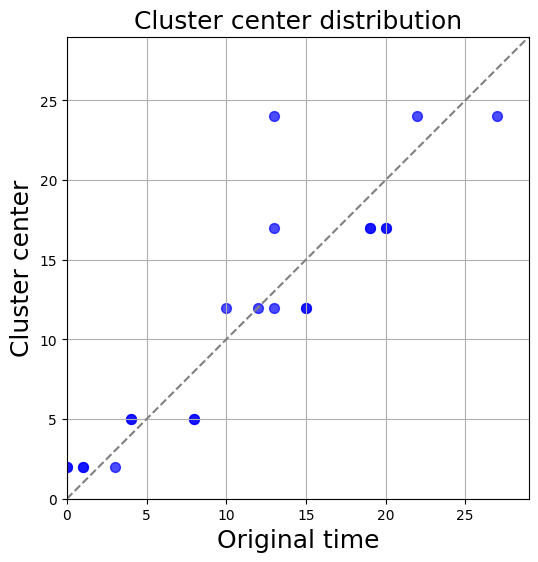

Center counts: CENTER
2     5
12    5
17    5
5     4
24    3
28    2
22    1
Name: count, dtype: int64
Results:
    INDEX  CSEM  INITIALP OPERATION  DATE  CENTER
0       0     0      3.27         x     1       2
1       1     0      3.27         x    10      12
2       2     0      3.27         x    19      17
3       3     0      3.27         y    28      28
4       4     1      3.35         x    13      24
5       5     2      3.21         x     0       2
6       6     2      3.21         x    15      12
7       7     3      3.26         x     3       2
8       8     3      3.26         x    19      17
9       9     4      3.39         x     4       5
10     10     4      3.39         x    12      12
11     11     4      3.39         x    20      17
12     12     4      3.39         y    28      28
13     13     5      3.36         x     4       5
14     14     5      3.36         x    13      12
15     15     5      3.36         x    22      24
16     16     6      3.27         x  

In [5]:
operation_x_count = (result_df['OPERATION'] == 'x').sum()
before_cost = operation_x_count * 10 
print(f"Cost before grouping: {before_cost}")

operation_x_center_unique_count = result_df[result_df['OPERATION'] == 'x']['CENTER'].nunique()
after_cost = operation_x_center_unique_count * 10 
print(f"Cost after grouping: {after_cost}")

df = pd.read_csv('maintenance_plan.csv')
leakage_before = round(calculate_gas_leakage_before(df, PARAMS['T']), 3)
print(f"Gas leakage before clustering: {leakage_before}")

leakage_after = round(calculate_gas_leakage_after(result_df, PARAMS['T']), 3)
print(f"Gas leakage after clustering: {leakage_after}")

df_x = df[df['OPERATION'] == 'x']
result_x = result_df[result_df['OPERATION'] == 'x']

plt.figure(figsize=(6, 6))
plt.scatter(df_x['DATE'], result_x['CENTER'], color='blue', alpha=0.7, s=50)
plt.title("Cluster center distribution", fontsize=18)
plt.xlabel("Original time", fontsize=18)
plt.ylabel("Cluster center", fontsize=18)
plt.grid(True)

max_range = max(result_x['DATE'].max(), result_x['CENTER'].max()+5)
plt.xlim(0, max_range)
plt.ylim(0, max_range)

plt.plot([0, max_range], [0, max_range], color='gray', linestyle='--', label='45° diagonal')
plt.gca().set_aspect('equal')
plt.show()

center_counts = result_df['CENTER'].value_counts()
print("Center counts:", center_counts)
print("Results:")
print(result_df)

result_df.to_csv('result.csv', index=False)
print("Result saved to result.csv")
